# Task 1 · Evidence and study notebook
### Inductive biases, controlled interventions, and representations

**Purpose:** understand the implementation, inspect saved evidence, and export figures/tables for your own report. This notebook does not train a model, download weights, regenerate cue conflicts, or alter experiment results. It reads the completed Task 1 artifacts and writes only to `report_assets/` beside this notebook.

**Assignment alignment:** `ATML_PA1.pdf`, pages 2–5 (Task 1), pages 16–17 (Task 5 and submission), and page 1 (AI policy). The manual requires the report's wording, interpretation, and analysis to be your own. Treat the explanations and possible mechanisms here as study notes, not prose to paste into the PDF. Write your own conclusions using the displayed evidence. Attribute materially reused code in your repository README.

**How to use:** choose the existing `Python (pa1_env)` kernel, restart it, and Run All. The delivered notebook includes executed outputs. Figures are exported as 220-dpi PNG and vector SVG; tables are CSV. `report_assets/asset_index.csv` maps outputs to their purpose. Image IDs and source hashes are recorded for traceability.

Contents: protocol → six-step walkthrough → data and intervention examples → learning curves → clean/color/patch evidence → cue conflicts → translations → representations → four model dossiers → research questions → Task 5 bridge and report checklist.

In [2]:
from pathlib import Path
import json, hashlib, sys
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from torchvision import datasets, transforms
from torchvision.transforms import functional as TF, InterpolationMode
from torch.utils.data import Dataset
from IPython.display import display, Markdown, Image

anchors = [Path.cwd(), *Path.cwd().parents]
TASK = next((q for p in anchors for q in (p, p/'task1', p/'Task 1')
             if (q/'configs/protocol.json').is_file() and (q/'results/clean_baseline.pt').is_file()), None)
if TASK is None:
    raise FileNotFoundError('Run from PA1, Task 1, or a folder within Task 1.')
TASK = TASK.resolve()
RESULTS = TASK/'results'
OUT = TASK/'report_assets'
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'figure.facecolor': 'white', 'savefig.facecolor': 'white'})
MODELS = ['ResNet-50 + linear head', 'ViT-B/16 + linear head',
          'CLIP ViT-B/32 + linear head', 'CLIP ViT-B/32 zero-shot']
SHORT = dict(zip(MODELS, ['ResNet-50 head', 'ViT-B/16 head', 'CLIP head', 'CLIP zero-shot']))
BACKBONES = ['resnet50', 'vit_b16', 'clip']
BNAMES = dict(zip(BACKBONES, ['ResNet-50', 'ViT-B/16', 'CLIP ViT-B/32']))
COLORS = dict(zip(MODELS, ['#0072B2', '#D55E00', '#009E73', '#CC79A7']))
assets, sources = [], set()
def csv(relative):
    p = RESULTS/relative; sources.add(p)
    return pd.read_csv(p)
def pt(relative):
    p = RESULTS/relative; sources.add(p)
    return torch.load(p, map_location='cpu', weights_only=True)
def table(df, name, purpose):
    df.to_csv(OUT/(name+'.csv'), index=False)
    assets.append({'file':name+'.csv', 'purpose':purpose})
    display(df.round(3))
def figure(fig, name, purpose):
    for suffix in ['png', 'svg']:
        fig.savefig(OUT/(name+'.'+suffix), dpi=220, bbox_inches='tight')
        assets.append({'file':name+'.'+suffix, 'purpose':purpose})
    plt.close(fig)
    display(Image(filename=str(OUT/(name+'.png'))))
def show(ax, x, title):
    ax.imshow(x.detach().cpu().permute(1,2,0).clamp(0,1).numpy())
    ax.set_title(title, fontsize=10); ax.axis('off')
baseline = pt('clean_baseline.pt')
cue = pt('cue_conflict_evaluation.pt')
perms = pt('patch_shuffle/patch_permutations.pt')
classes = baseline['class_names']
ids = baseline['test_indices'].numpy()
clean = csv('clean_metrics.csv')
color = csv('color_metrics.csv')
patch = csv('patch_shuffle/patch_metrics.csv')
shape = csv('shape_texture_metrics.csv')
translation = csv('translation/translation_summary.csv')
manifest = csv('cue_conflict_manifest.csv')
cue_predictions = csv('cue_conflict_predictions.csv')
review = csv('cue_conflict_review_log.csv')
stability = csv('representation_analysis/stability_summary.csv')
pred_summary = csv('representation_analysis/prediction_summary.csv')
pred_pairs = csv('representation_analysis/prediction_pairs.csv')
clean_predictions = csv('clean_predictions.csv')
test_data = datasets.STL10(str(TASK/'data'), split='test', download=False)
train_data = datasets.STL10(str(TASK/'data'), split='train', download=False)
preprocess = transforms.Compose([transforms.Resize((224,224), interpolation=InterpolationMode.BICUBIC,
                                                 antialias=True), transforms.ToTensor()])
def rgb(index, split='test'):
    ds = test_data if split == 'test' else train_data
    return preprocess(ds[int(index)][0].convert('RGB'))
# Load only the already-inspected transformation function definitions, not the experiment runner.
SEED=6304; GRID_SIZE=4; PATCH_SIZE=56
source = TASK/'data/transforms.ipynb'; sources.add(source)
for c in json.loads(source.read_text(encoding='utf-8'))['cells']:
    if c['cell_type']=='code': exec(compile(''.join(c['source']), str(source), 'exec'), globals())
assert len(ids)==500 and len(set(ids))==500
assert torch.equal(perms['test_indices'], baseline['test_indices'])
assert np.array_equal(cue['content_indices'].numpy(), manifest.content_index.to_numpy())
assert np.array_equal(cue['style_indices'].numpy(), manifest.style_index.to_numpy())
assert manifest.groupby('direction').size().eq(20).all()
assert set(baseline['train_indices'].tolist()).isdisjoint(baseline['val_indices'].tolist())
for model in MODELS:
    rows = clean_predictions[clean_predictions.model==model]
    assert set(rows.official_test_index)==set(ids)
    assert np.isclose((rows.label==rows.predicted_label).mean(), clean.set_index('model').loc[model,'top1_accuracy'])
    pred=cue['logits'][model].argmax(1)
    counts=[int((pred==cue['content_targets']).sum()), int((pred==cue['style_targets']).sum())]
    saved=shape.set_index('model').loc[model]
    assert counts==[saved.Nshape,saved.Ntexture]
print('Checked paired IDs, splits, clean accuracies, and cue counts against saved predictions.')
print('Python:', sys.executable, '\nOutputs:', OUT)


Checked paired IDs, splits, clean accuracies, and cue counts against saved predictions.
Python: c:\Users\Taha\miniconda3\envs\pa1_env\python.exe 
Outputs: D:\LUMS GAMING\6. 2026 Fall\CS 6304\Programming Assignments\PA1\Task 1\task1\report_assets


## 1. What is this task doing, and how?

The same 500 test images are viewed through four decision rules: a frozen ResNet-50 plus a trained linear head, a frozen ViT-B/16 plus a trained linear head, a frozen CLIP image encoder plus a trained linear head, and CLIP zero-shot. Only the three linear heads are trained. A transformation changes the image **before** model-specific normalization; the fixed model then predicts again.

The experiment separates three questions:

1. **Recognition:** does the transformed input still receive its true class? Accuracy and macro-F1 answer this.
2. **Decision stability:** does its prediction stay the same as on its clean counterpart? Consistency can be high even if both predictions are wrong.
3. **Representation stability:** how similar are the clean/transformed feature vectors? Mean cosine similarity measures this; it is not classification accuracy.

CLIP head versus zero-shot is especially useful because both use the same image representation but different decision rules. Across ResNet, ViT, and CLIP, architecture, pretraining, capacity, normalization, and supervision are not isolated experimentally.

### Fixed protocol and model outputs

Official STL-10 training images: 4,000 train / 1,000 validation; 80/20 stratified split with seed 6304. Official test: 500 saved IDs, 50 per class. Common RGB geometry: bicubic 224×224. Head optimizer: AdamW, learning rate 0.001, weight decay 0.0001, batch size 256, at most 50 epochs, patience 5 based on validation accuracy. The selected head is the **first** epoch reaching the best validation accuracy, not the final epoch. Zero-shot uses the fixed prompt `a photo of a {class}.` and has no fitted head or training history.

Saved `clean_baseline.pt` contains split IDs, three head states, clean features/logits, and three histories. Backbone weights come from the prescribed public pretrained models; they are not newly trained Task 1 models.

| Frozen encoder | Pretrained weights | Feature used by the head |
|---|---|---|
| ResNet-50 | torchvision `ResNet50_Weights.IMAGENET1K_V2` | 2,048-dimensional global-average-pooled feature |
| ViT-B/16 | torchvision `ViT_B_16_Weights.IMAGENET1K_V1` | 768-dimensional final class token |
| CLIP ViT-B/32 | OpenCLIP `ViT-B-32`, `pretrained="openai"` | 512-dimensional L2-normalized image embedding |

Each linear head produces ten STL-10 logits. CLIP zero-shot instead scores the same image embedding against the ten prompted class embeddings and takes the largest scaled similarity. Softmax supplies confidence; the largest score supplies the prediction.

In [3]:
rows=[]
for b,m in zip(BACKBONES,MODELS):
    h=pd.DataFrame(baseline['training_histories'][b]); best=h.loc[h.val_accuracy.idxmax()]
    rows.append(dict(model=SHORT[m], representation_dimension=baseline['clean_test_features'][b].shape[1],
                     trainable_parameters=sum(t.numel() for t in baseline['head_states'][b].values()),
                     selected_epoch=int(best.epoch), epochs_run=int(h.epoch.max()),
                     best_validation_accuracy_pct=100*best.val_accuracy))
table(pd.DataFrame(rows), '01_model_protocol', 'Head dimensions, selected epochs, and validation performance')
split_counts=pd.DataFrame({'class':classes,
    'train':[sum(train_data.labels[baseline['train_indices'].numpy()]==i) for i in range(10)],
    'validation':[sum(train_data.labels[baseline['val_indices'].numpy()]==i) for i in range(10)],
    'test_subset':[sum(test_data.labels[ids]==i) for i in range(10)]})
table(split_counts,'02_split_counts','Exact class balance from saved split IDs')


,model,representation_dimension,trainable_parameters,selected_epoch,epochs_run,best_validation_accuracy_pct
0,ResNet-50 head,2048,20490,11,16,97.2
1,ViT-B/16 head,768,7690,19,24,98.0
2,CLIP head,512,5130,4,9,98.4


,class,train,validation,test_subset
0,airplane,400,100,50
1,bird,400,100,50
2,car,400,100,50
3,cat,400,100,50
4,deer,400,100,50
5,dog,400,100,50
6,horse,400,100,50
7,monkey,400,100,50
8,ship,400,100,50
9,truck,400,100,50


## 2. What each step does and produces

| Step | Operation and comparison | Saved output and interpretation boundary |
|---|---|---|
| 1 · Clean | Extract frozen features; train/validate three linear heads; evaluate these and zero-shot CLIP on the same test IDs. | `clean_baseline.pt`, `clean_metrics.csv`, `clean_predictions.csv`; these establish each model's reference performance. |
| 2 · Color | Grayscale removes chromatic variation; hue +0.25 changes hue while leaving geometry fixed. Use identical transformed tensors for every model. | `color_evaluation.pt`, `color_metrics.csv`, `color_predictions.csv`; report absolute accuracy, change in percentage points, and consistency. |
| 3 · Shape/texture | Evaluate 200 preserved optimization-based VGG style-transfer conflicts: five unordered pairs, two directions, 20 per direction. Content supplies shape; donor supplies style. | Protected images/review log, predictions, shape/texture/other counts, shape bias and coverage. No new classifier or style-transfer training is performed here. |
| 4 · Translation | Reflection pad and shifted crop at 0/8/16/32 px; left/right/up/down. Average the four directions at nonzero shifts. | `translation/`: frozen-feature caches, per-direction and aggregate CSVs; no head retraining. |
| 5 · Patch structure | One saved non-identity 4×4 patch permutation per image, seed 6304; 56×56 px patches. Reuse it across models. | `patch_shuffle/`: exact permutations, features, predictions and metrics. Pixels and local patch content are retained; global arrangement changes. |
| 6 · Representations | Pair clean/transformed embeddings; cosine similarity; one shared t-SNE fit per backbone combining conditions. | `representation_analysis/`: pair-level metrics, summaries, mismatch cases, coordinates/settings. The two CLIP decision rules share one image embedding. |

**Definitions:** accuracy = correct / total; consistency = unchanged prediction / paired images; accuracy change = transformed − clean (percentage points); patch accuracy *drop* in its original CSV uses clean − shuffled instead. Shape bias = shape / (shape + texture); coverage = (shape + texture) / total. A cue-conflict image has two intended labels, so shape bias is not ordinary accuracy.

**Style-transfer provenance gap:** the current files preserve the generated tensors and visual decisions, but do not fully document the original style weight/strength or optimization settings. Do not invent these. Consult an archived generator/config if available before describing exact style-transfer hyperparameters. The review log records rejection reasons, but a saved log alone does not establish when every decision was made.

In [4]:
rejection_counts=review.groupby(['accepted','reason']).size().rename('count').reset_index()
table(rejection_counts,'03_cue_review_counts','Accepted/rejected counts and recorded visual criteria')
table(manifest.groupby(['pair','direction']).size().rename('accepted_conflicts').reset_index(),
      '04_cue_balance','Five pairs, both directions, exact retained counts')


,accepted,reason,count
0,False,Only background color transferred; no visible ...,375
1,True,Content outline remains clear; style surface p...,200


,pair,direction,accepted_conflicts
0,airplane / ship,airplane -> ship,20
1,airplane / ship,ship -> airplane,20
2,bird / monkey,bird -> monkey,20
3,bird / monkey,monkey -> bird,20
4,car / truck,car -> truck,20
5,car / truck,truck -> car,20
6,cat / dog,cat -> dog,20
7,cat / dog,dog -> cat,20
8,deer / horse,deer -> horse,20
9,deer / horse,horse -> deer,20


## 3. Actual training/test examples and one-image intervention panel

The first grid contains one saved **training** example and one fixed **test** example for each class. These are different images; train and test IDs belong to different official partitions.

The second figure uses content image from cue-conflict row 50 for every transformation. Its donor is explicitly labeled as a different image. Patch order is the saved order for this exact test ID; translation uses the experiment's reflection-padding function. The cue image is loaded from the preserved archive, never regenerated. This example was chosen for visible object geometry and display clarity, not as an estimate of typical model performance.

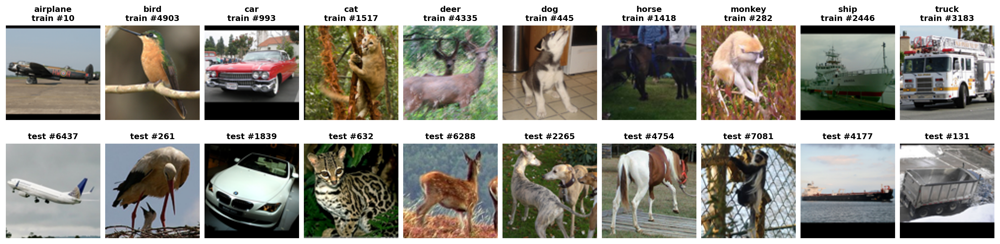

,split,index,label
0,train,10,airplane
1,test,6437,airplane
2,train,4903,bird
3,test,261,bird
4,train,993,car
5,test,1839,car
6,train,1517,cat
7,test,632,cat
8,train,4335,deer
9,test,6288,deer


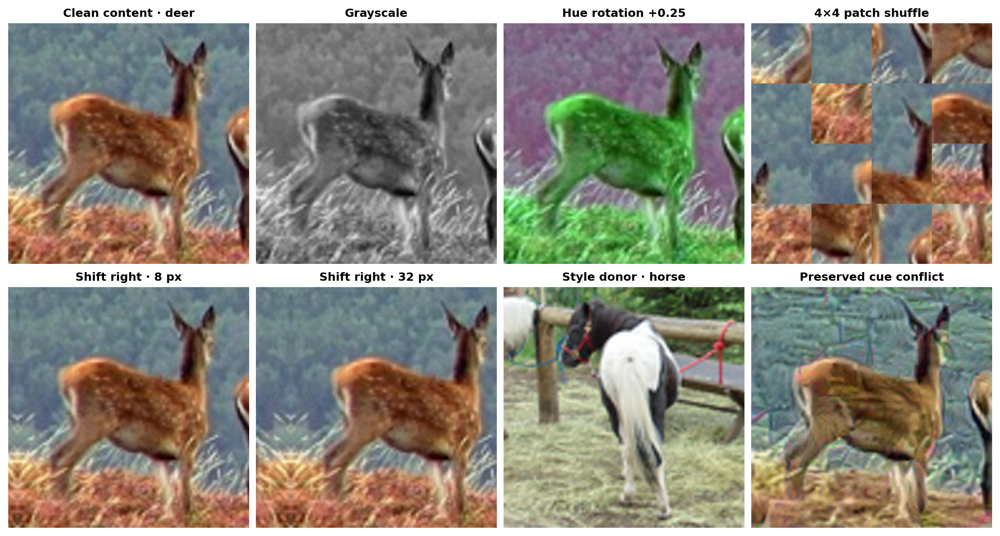

,cue_row,content_test_id,style_test_id,direction,patch_subset_row
0,50,6288,7726,deer -> horse,21


In [5]:
fig,axs=plt.subplots(2,10,figsize=(17,4.2),layout='constrained')
example_rows=[]
for label in range(10):
    tr=next(int(i) for i in baseline['train_indices'] if train_data.labels[int(i)]==label)
    te=next(int(i) for i in ids if test_data.labels[int(i)]==label)
    show(axs[0,label],rgb(tr,'train'),f'{classes[label]}\ntrain #{tr}')
    show(axs[1,label],rgb(te),f'test #{te}')
    example_rows.extend([dict(split='train',index=tr,label=classes[label]),dict(split='test',index=te,label=classes[label])])
figure(fig,'05_train_test_examples','One real training and held-out test example per class')
table(pd.DataFrame(example_rows),'05_example_ids','Official partition IDs for the sample grid')

EXAMPLE_CUE=50
row=manifest.iloc[EXAMPLE_CUE]; example_id=int(row.content_index)
position=int(np.flatnonzero(ids==example_id)[0]); x=rgb(example_id)
variants=[('Clean content · '+classes[int(row.content_label)],x),
          ('Grayscale',TF.rgb_to_grayscale(x,3)),('Hue rotation +0.25',TF.adjust_hue(x,0.25)),
          ('4×4 patch shuffle',shuffle_patches(x,perms['permutations'][position])),
          ('Shift right · 8 px',translate_rgb(x,8,0)),('Shift right · 32 px',translate_rgb(x,32,0)),
          ('Style donor · '+classes[int(row.style_label)],rgb(row.style_index)),
          ('Preserved cue conflict',cue['images'][EXAMPLE_CUE])]
fig,axs=plt.subplots(2,4,figsize=(12,6.4),layout='constrained')
for ax,(title,img) in zip(axs.flat,variants):show(ax,img,title)
figure(fig,'06_same_image_interventions','Same content image across interventions; style donor separately identified')
table(pd.DataFrame([dict(cue_row=EXAMPLE_CUE,content_test_id=example_id,style_test_id=int(row.style_index),
                         direction=row.direction,patch_subset_row=position)]),'06_intervention_ids','Image and permutation provenance')


## 4. Saved training curves: three heads, overlaid by epoch

Training loss and validation accuracy are available. **Training accuracy and validation loss were not logged**, so they cannot be reconstructed reliably from the selected checkpoint. Test accuracy was measured after selection, not every epoch. Zero-shot CLIP has no training curve. Curves stop where the saved run stopped; no extrapolation or padding is used. Stars mark the selected epoch.

Study note: accuracy depends on the largest logit, whereas cross-entropy depends on the probability assigned to the true class. Correct rankings can coexist with low confidence and relatively high loss. CLIP's unit-normalized features also differ in scale from the other feature types, so equal optimizer settings do not make raw loss values a pure architecture comparison.

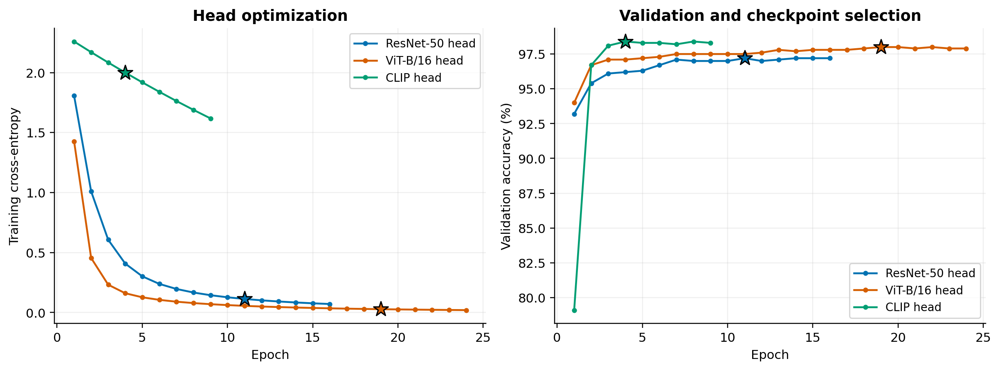

,epoch,train_loss,val_accuracy,model
0,1,1.807,0.932,ResNet-50 head
1,2,1.010,0.954,ResNet-50 head
2,3,0.606,0.961,ResNet-50 head
3,4,0.408,0.962,ResNet-50 head
4,5,0.302,0.963,ResNet-50 head
5,6,0.238,0.967,ResNet-50 head
6,7,0.196,0.971,ResNet-50 head
7,8,0.167,0.970,ResNet-50 head
8,9,0.144,0.970,ResNet-50 head
9,10,0.127,0.970,ResNet-50 head


In [6]:
fig,axs=plt.subplots(1,2,figsize=(11,4),layout='constrained'); histories=[]
for b,m in zip(BACKBONES,MODELS):
    h=pd.DataFrame(baseline['training_histories'][b]); best=h.loc[h.val_accuracy.idxmax()]
    histories.append(h.assign(model=SHORT[m]))
    axs[0].plot(h.epoch,h.train_loss,'o-',ms=3,color=COLORS[m],label=SHORT[m])
    axs[1].plot(h.epoch,100*h.val_accuracy,'o-',ms=3,color=COLORS[m],label=SHORT[m])
    axs[0].scatter(best.epoch,best.train_loss,marker='*',s=150,color=COLORS[m],edgecolor='black',zorder=5)
    axs[1].scatter(best.epoch,100*best.val_accuracy,marker='*',s=150,color=COLORS[m],edgecolor='black',zorder=5)
for ax,title,ylabel in zip(axs,['Head optimization','Validation and checkpoint selection'],['Training cross-entropy','Validation accuracy (%)']):
    ax.set(title=title,xlabel='Epoch',ylabel=ylabel);ax.grid(alpha=.2);ax.legend(fontsize=9)
figure(fig,'07_training_curves','Actual saved loss and validation accuracy, all heads overlaid')
table(pd.concat(histories,ignore_index=True),'07_training_history','Raw saved epoch histories; accuracy is a fraction')


## 5. Clean, color, and patch results

Use both absolute accuracy and change from each model's own baseline. This table includes macro-F1, mean maximum confidence, and prediction consistency. All displayed rate columns below are percentages; changes are percentage points. Mean confidence is not a calibration score, and softmax scales differ across heads and zero-shot CLIP.

,model,condition,accuracy_pct,macro_f1_pct,confidence_pct,change_pp,consistency_pct
0,ResNet-50 head,Clean,97.6,97.606,89.784,0.0,100.0
1,ResNet-50 head,Grayscale,95.8,95.783,90.350,-1.8,96.6
2,ResNet-50 head,Hue +0.25,92.8,92.777,88.743,-4.8,94.0
3,ResNet-50 head,Patch shuffle,87.4,87.505,87.109,-10.2,89.8
4,ViT-B/16 head,Clean,97.4,97.389,95.898,0.0,100.0
5,ViT-B/16 head,Grayscale,95.4,95.392,95.316,-2.0,95.0
6,ViT-B/16 head,Hue +0.25,95.0,95.001,92.697,-2.4,94.8
7,ViT-B/16 head,Patch shuffle,90.6,90.640,88.442,-6.8,91.8
8,CLIP head,Clean,97.2,97.193,14.197,0.0,100.0
9,CLIP head,Grayscale,95.6,95.564,13.783,-1.6,94.8


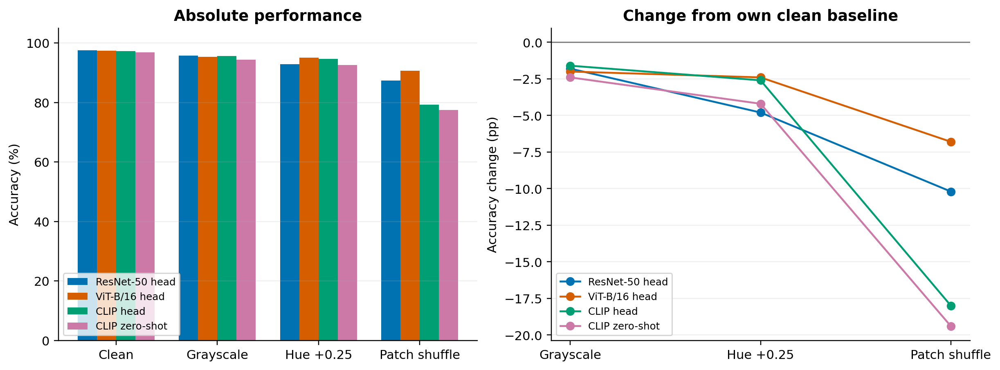

In [7]:
records=[]
for m in MODELS:
    c=clean.set_index('model').loc[m]
    records.append(dict(model=SHORT[m],condition='Clean',accuracy_pct=100*c.top1_accuracy,
        macro_f1_pct=100*c.macro_f1,confidence_pct=100*c.mean_max_confidence,change_pp=0.,consistency_pct=100.))
    for _,v in color[color.model==m].iterrows():
        records.append(dict(model=SHORT[m],condition={'grayscale':'Grayscale','hue_rotation':'Hue +0.25'}[v.condition],
            accuracy_pct=100*v.top1_accuracy,macro_f1_pct=100*v.macro_f1,confidence_pct=100*v.mean_max_confidence,
            change_pp=100*(v.top1_accuracy-c.top1_accuracy),consistency_pct=100*v.prediction_consistency))
    v=patch.set_index('model').loc[m]
    records.append(dict(model=SHORT[m],condition='Patch shuffle',accuracy_pct=100*v.shuffled_accuracy,
        macro_f1_pct=100*v.macro_f1,confidence_pct=100*v.mean_max_confidence,
        change_pp=100*(v.shuffled_accuracy-c.top1_accuracy),consistency_pct=100*v.prediction_consistency))
comparison=pd.DataFrame(records)
table(comparison,'08_performance_comparison','Clean/color/patch performance on the common 500-image subset')
fig,axs=plt.subplots(1,2,figsize=(11,4),layout='constrained')
conditions=['Clean','Grayscale','Hue +0.25','Patch shuffle']
for j,m in enumerate(MODELS):
    d=comparison[comparison.model==SHORT[m]].set_index('condition').loc[conditions]
    axs[0].bar(np.arange(4)+(j-1.5)*.19,d.accuracy_pct,width=.19,color=COLORS[m],label=SHORT[m])
    axs[1].plot(np.arange(3),d.change_pp.iloc[1:],'o-',color=COLORS[m],label=SHORT[m])
axs[0].set(xticks=np.arange(4),xticklabels=conditions,ylabel='Accuracy (%)',ylim=(0,105),title='Absolute performance')
axs[1].set(xticks=np.arange(3),xticklabels=conditions[1:],ylabel='Accuracy change (pp)',title='Change from own clean baseline')
axs[1].axhline(0,color='gray',lw=1)
for ax in axs:ax.grid(axis='y',alpha=.2)
axs[0].legend(fontsize=8,loc='lower left')
axs[1].legend(fontsize=8,loc='lower left')
figure(fig,'09_intervention_comparison','Absolute performance and baseline-relative sensitivity')


## 6. Shape, texture, coverage, and informative examples

Interpret the two rightmost metrics together: a large shape-bias value is conditional on predicting one of the intended labels. The stacked bars retain the **other** decisions that shape bias excludes. Direction-specific values reveal asymmetry hidden by the overall average.

The three illustrated cases were chosen from the already fixed evaluation set for readable examples of agreement, shape/texture disagreement, and an off-pair failure. These are illustrative cases, not an unbiased sample. Choosing a reporting example after evaluation must not change which images contribute to aggregate metrics.

,model,Nshape,Ntexture,Nother,Ntotal,shape_bias_pct,coverage_pct
0,ResNet-50 head,108,77,15,200,58.378,92.5
1,ViT-B/16 head,154,37,9,200,80.628,95.5
2,CLIP head,137,47,16,200,74.457,92.0
3,CLIP zero-shot,131,48,21,200,73.184,89.5


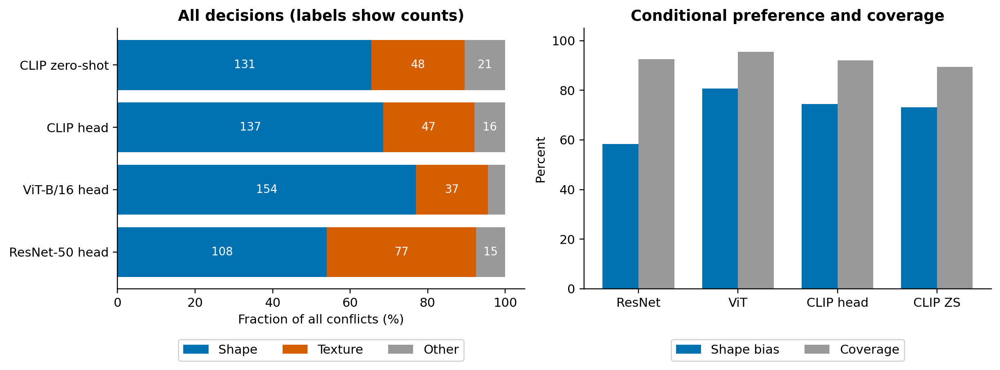

,model,direction,Nshape,Ntexture,Nother,Ntotal,shape_bias_pct,coverage_pct
0,ResNet-50 head,cat -> dog,18,2,0,20,90.000,100.0
1,ResNet-50 head,dog -> cat,11,5,4,20,68.750,80.0
2,ResNet-50 head,deer -> horse,12,8,0,20,60.000,100.0
3,ResNet-50 head,horse -> deer,12,7,1,20,63.158,95.0
4,ResNet-50 head,bird -> monkey,10,6,4,20,62.500,80.0
5,ResNet-50 head,monkey -> bird,3,13,4,20,18.750,80.0
6,ResNet-50 head,car -> truck,8,12,0,20,40.000,100.0
7,ResNet-50 head,truck -> car,13,6,1,20,68.421,95.0
8,ResNet-50 head,airplane -> ship,9,10,1,20,47.368,95.0
9,ResNet-50 head,ship -> airplane,12,8,0,20,60.000,100.0


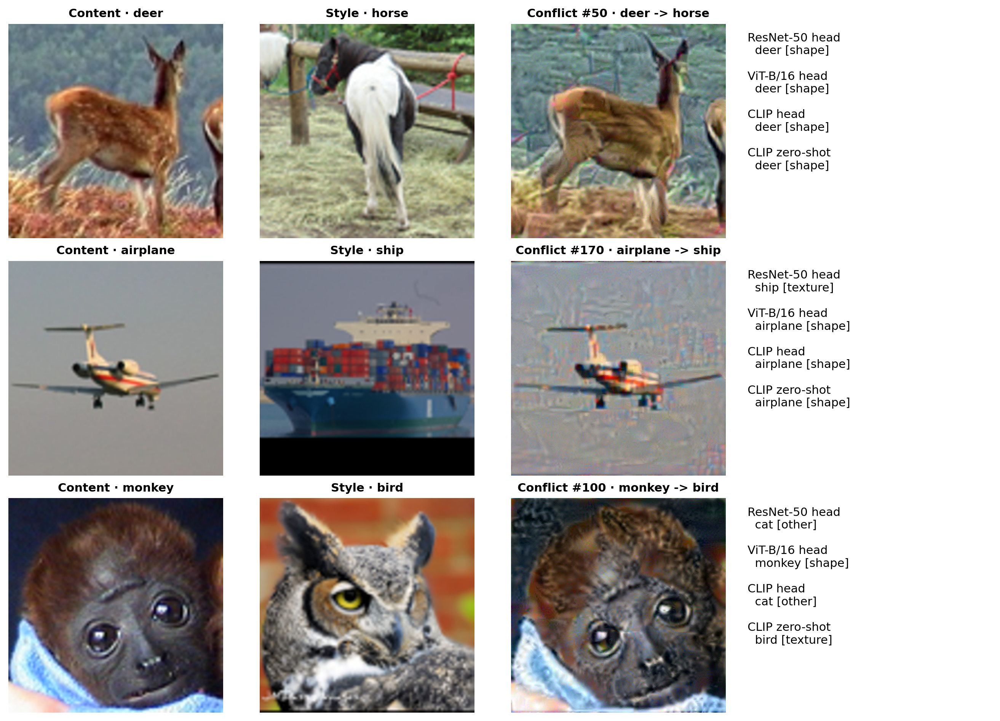

,cue_row,content_test_id,style_test_id,model,prediction,decision
0,50,6288,7726,ResNet-50 head,deer,shape
1,50,6288,7726,ViT-B/16 head,deer,shape
2,50,6288,7726,CLIP head,deer,shape
3,50,6288,7726,CLIP zero-shot,deer,shape
4,170,4893,1833,ResNet-50 head,ship,texture
5,170,4893,1833,ViT-B/16 head,airplane,shape
6,170,4893,1833,CLIP head,airplane,shape
7,170,4893,1833,CLIP zero-shot,airplane,shape
8,100,1579,2116,ResNet-50 head,cat,other
9,100,1579,2116,ViT-B/16 head,monkey,shape


In [8]:
table(shape.assign(model=shape.model.map(SHORT)),'10_shape_texture','Counts, shape bias, and coverage; 200 conflicts per model')
fig,axs=plt.subplots(1,2,figsize=(11,4),layout='constrained')
d=shape.set_index('model').loc[MODELS];left=np.zeros(4)
for col,label,c in [('Nshape','Shape','#0072B2'),('Ntexture','Texture','#D55E00'),('Nother','Other','#999999')]:
    widths=100*d[col]/d.Ntotal
    axs[0].barh(range(4),widths,left=left,label=label,color=c)
    for i,w in enumerate(widths):
        if w>5:axs[0].text(left[i]+w/2,i,f'{int(d.iloc[i][col])}',ha='center',va='center',color='white',fontsize=9)
    left+=widths.to_numpy()
axs[0].set(yticks=range(4),yticklabels=[SHORT[m] for m in MODELS],xlabel='Fraction of all conflicts (%)',title='All decisions (labels show counts)')
axs[0].legend(loc='upper center',bbox_to_anchor=(.5,-.17),ncol=3)
axs[1].bar(np.arange(4)-.18,d.shape_bias_pct,.36,label='Shape bias',color='#0072B2')
axs[1].bar(np.arange(4)+.18,d.coverage_pct,.36,label='Coverage',color='#999999')
axs[1].set(xticks=range(4),xticklabels=['ResNet','ViT','CLIP head','CLIP ZS'],ylim=(0,105),ylabel='Percent',title='Conditional preference and coverage')
axs[1].legend(loc='upper center',bbox_to_anchor=(.5,-.17),ncol=2)
figure(fig,'11_shape_coverage','Shape/texture/other counts with shape bias and coverage')
direction=csv('shape_texture_by_direction.csv')
table(direction.assign(model=direction.model.map(SHORT)),'12_direction_results','Shape/texture results by content-to-style direction')

chosen=[50,170,100]; fig,axs=plt.subplots(3,4,figsize=(12,8.5),layout='constrained')
example_predictions=[]
for row_number,i in enumerate(chosen):
    r=manifest.iloc[i]
    show(axs[row_number,0],rgb(r.content_index),'Content · '+classes[int(r.content_label)])
    show(axs[row_number,1],rgb(r.style_index),'Style · '+classes[int(r.style_label)])
    show(axs[row_number,2],cue['images'][i],f'Conflict #{i} · {r.direction}')
    p=cue_predictions[cue_predictions.candidate_id==r.candidate_id].set_index('model').loc[MODELS]
    lines=[]
    for m in MODELS:
        v=p.loc[m]; lines.append(f'{SHORT[m]}\n  {v.predicted_class} [{v.decision}]')
        example_predictions.append(dict(cue_row=i,content_test_id=int(r.content_index),style_test_id=int(r.style_index),
                                         model=SHORT[m],prediction=v.predicted_class,decision=v.decision))
    axs[row_number,3].axis('off');axs[row_number,3].text(0,.96,'\n\n'.join(lines),va='top',fontsize=10)
figure(fig,'13_cue_cases','Content, style donor, preserved conflict, and all four predictions')
table(pd.DataFrame(example_predictions),'13_cue_case_predictions','Traceable predictions for illustrated cue-conflict cases')


## 7. Translation: response to displacement

The four directions are averaged equally. At each nonzero displacement there are 500 images × 4 directions; those are repeated views of the same images, not 2,000 independent test examples. The clean point is included once. Reflection padding changes boundary context as well as position, so this is not a pure test of internal translation equivariance.

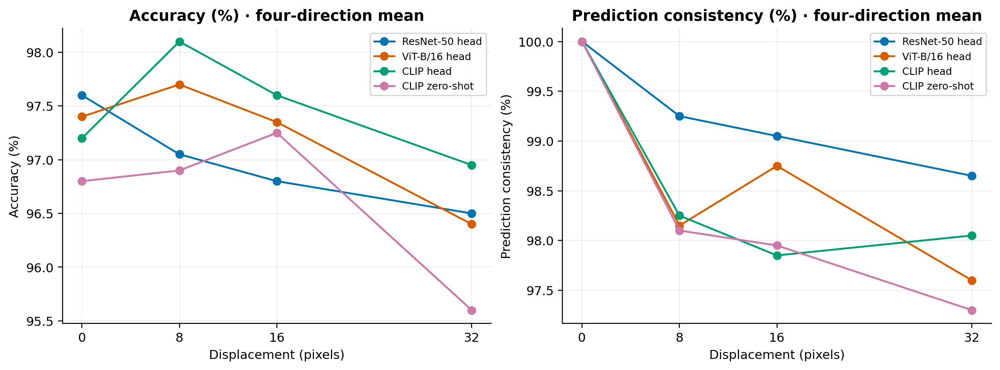

,model,displacement,accuracy,prediction_consistency,accuracy_change_pp
0,CLIP head,0,0.972,1.000,0.00
1,CLIP head,8,0.981,0.983,0.90
2,CLIP head,16,0.976,0.978,0.40
3,CLIP head,32,0.970,0.981,-0.25
4,CLIP zero-shot,0,0.968,1.000,0.00
5,CLIP zero-shot,8,0.969,0.981,0.10
6,CLIP zero-shot,16,0.973,0.980,0.45
7,CLIP zero-shot,32,0.956,0.973,-1.20
8,ResNet-50 head,0,0.976,1.000,0.00
9,ResNet-50 head,8,0.971,0.993,-0.55


In [9]:
fig,axs=plt.subplots(1,2,figsize=(11,4),layout='constrained')
for m in MODELS:
    d=translation[translation.model==m].sort_values('displacement')
    for ax,col in zip(axs,['accuracy','prediction_consistency']):
        ax.plot(d.displacement,100*d[col],'o-',color=COLORS[m],label=SHORT[m])
for ax,title in zip(axs,['Accuracy (%)','Prediction consistency (%)']):
    ax.set(xlabel='Displacement (pixels)',ylabel=title,xticks=[0,8,16,32],title=title+' · four-direction mean')
    ax.grid(alpha=.2);ax.legend(fontsize=8)
figure(fig,'14_translation_curves','Accuracy and consistency versus displacement')
table(translation.assign(model=translation.model.map(SHORT)),'14_translation_values','Source values; rate columns remain fractions')


## 8. Prediction versus representation

Cosine stability averages paired feature vectors in their original feature space. The plots below show all required intervention families. Translation panels use the four-direction average at each displacement. Cue conflicts have 200 pairs, whereas other interventions use 500 images; the content IDs can repeat across distinct cue conflicts.

The scatter keeps prediction consistency separate from cosine stability. Its diagonal is only a visual reference between two different quantities, not a theoretical equality. High cosine with a changed prediction can occur near a linear decision boundary; unchanged prediction with lower cosine can occur if the movement stays in the same decision region. Neither observation alone identifies which semantic cue caused the change.

,backbone,condition,cosine,n_pairs
0,ResNet-50,grayscale,0.789,500
1,ResNet-50,cue_conflict,0.465,200
2,ResNet-50,patch_shuffle,0.718,500
3,ResNet-50,translation_8,0.969,2000
4,ResNet-50,translation_16,0.952,2000
5,ResNet-50,translation_32,0.933,2000
6,ViT-B/16,grayscale,0.739,500
7,ViT-B/16,cue_conflict,0.489,200
8,ViT-B/16,patch_shuffle,0.653,500
9,ViT-B/16,translation_8,0.947,2000


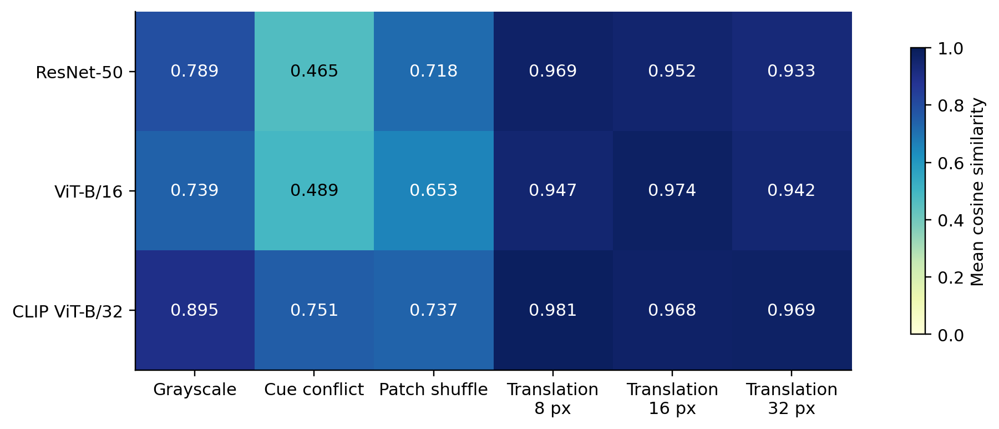

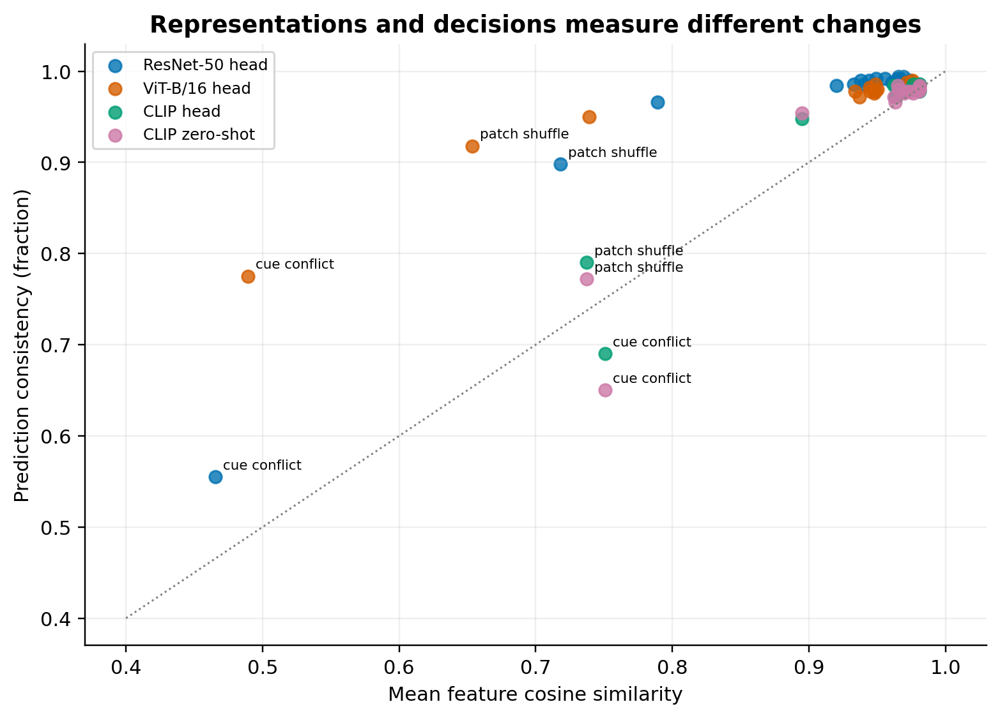

,backbone,condition,pair_index,official_test_index,content_label,cosine_similarity,model,clean_prediction,transformed_prediction,prediction_unchanged,example_type,clean_prediction_class,transformed_prediction_class
0,clip,patch_shuffle,223,49,2,0.565,CLIP ViT-B/32 + linear head,2,2,True,Lowest cosine among unchanged predictions,car,car
1,clip,patch_shuffle,435,6332,2,0.577,CLIP ViT-B/32 + linear head,2,2,True,Lowest cosine among unchanged predictions,car,car
2,clip,patch_shuffle,250,4735,2,0.584,CLIP ViT-B/32 + linear head,2,2,True,Lowest cosine among unchanged predictions,car,car
3,clip,translation_08_up,411,568,5,0.991,CLIP ViT-B/32 + linear head,3,5,False,Highest cosine among changed predictions,cat,dog
4,clip,translation_08_left,102,7413,5,0.990,CLIP ViT-B/32 + linear head,3,7,False,Highest cosine among changed predictions,cat,monkey
5,clip,translation_32_down,191,3562,3,0.988,CLIP ViT-B/32 + linear head,3,4,False,Highest cosine among changed predictions,cat,deer
6,clip,patch_shuffle,223,49,2,0.565,CLIP ViT-B/32 zero-shot,2,2,True,Lowest cosine among unchanged predictions,car,car
7,clip,patch_shuffle,435,6332,2,0.577,CLIP ViT-B/32 zero-shot,2,2,True,Lowest cosine among unchanged predictions,car,car
8,clip,patch_shuffle,488,419,9,0.588,CLIP ViT-B/32 zero-shot,9,9,True,Lowest cosine among unchanged predictions,truck,truck
9,clip,translation_32_down,299,2536,3,0.991,CLIP ViT-B/32 zero-shot,3,4,False,Highest cosine among changed predictions,cat,deer


In [10]:
trans_stability=csv('representation_analysis/translation_stability.csv')
rep_rows=[]
for b in BACKBONES:
    for cond in ['grayscale','cue_conflict','patch_shuffle']:
        v=stability[(stability.backbone==b)&(stability.condition==cond)].iloc[0]
        rep_rows.append(dict(backbone=BNAMES[b],condition=cond,cosine=v.mean_cosine,n_pairs=int(v.n_pairs)))
    for _,v in trans_stability[trans_stability.backbone==b].iterrows():
        rep_rows.append(dict(backbone=BNAMES[b],condition=f'translation_{int(v.displacement)}',cosine=v.mean_cosine,
                             n_pairs=int(v.n_image_direction_pairs)))
rep_table=pd.DataFrame(rep_rows)
table(rep_table,'15_representation_stability','Cosine stability for every required intervention family')
pivot=rep_table.pivot(index='backbone',columns='condition',values='cosine').reindex([BNAMES[b] for b in BACKBONES])
pivot=pivot[['grayscale','cue_conflict','patch_shuffle','translation_8','translation_16','translation_32']]
fig,ax=plt.subplots(figsize=(11,3.4),layout='constrained')
im=ax.imshow(pivot.values,vmin=0,vmax=1,cmap='YlGnBu')
ax.set(xticks=range(len(pivot.columns)),xticklabels=['Grayscale','Cue conflict','Patch shuffle','Translation\n8 px','Translation\n16 px','Translation\n32 px'],yticks=range(3),yticklabels=pivot.index)
for i in range(3):
    for j in range(len(pivot.columns)):
        ax.text(j,i,f'{pivot.iloc[i,j]:.3f}',ha='center',va='center',color='white' if pivot.iloc[i,j]>.55 else 'black')
fig.colorbar(im,ax=ax,label='Mean cosine similarity',shrink=.8)
figure(fig,'16_stability_heatmap','Compact original-feature-space stability comparison')

fig,ax=plt.subplots(figsize=(7,5),layout='constrained')
for m in MODELS:
    d=pred_summary[pred_summary.model==m]
    ax.scatter(d.mean_cosine,d.prediction_consistency,color=COLORS[m],label=SHORT[m],s=40,alpha=.8)
    for _,v in d[d.condition.isin(['cue_conflict','patch_shuffle'])].iterrows():
        ax.annotate(v.condition.replace('_',' '),(v.mean_cosine,v.prediction_consistency),fontsize=7,xytext=(4,4),textcoords='offset points')
ax.plot([.4,1],[.4,1],':',color='gray',lw=1)
ax.set(xlabel='Mean feature cosine similarity',ylabel='Prediction consistency (fraction)',title='Representations and decisions measure different changes')
ax.legend(fontsize=8);ax.grid(alpha=.2)
figure(fig,'17_prediction_vs_features','Paired representation stability versus decision consistency')
mismatches=csv('representation_analysis/mismatch_examples.csv')
table(mismatches,'18_mismatch_evidence','Saved high-cosine changes and low-cosine unchanged decisions')


### A concrete mismatch shown as image pairs

For each backbone, the panel chooses the lowest-cosine unchanged **patch-shuffle** prediction and the highest-cosine changed **translation** prediction from the saved pair-level data. The selection rule is diagnostic and intentionally extreme; it is not a prevalence estimate. Both original and transformed predictions are displayed, including cases where a transformation corrects a clean mistake.

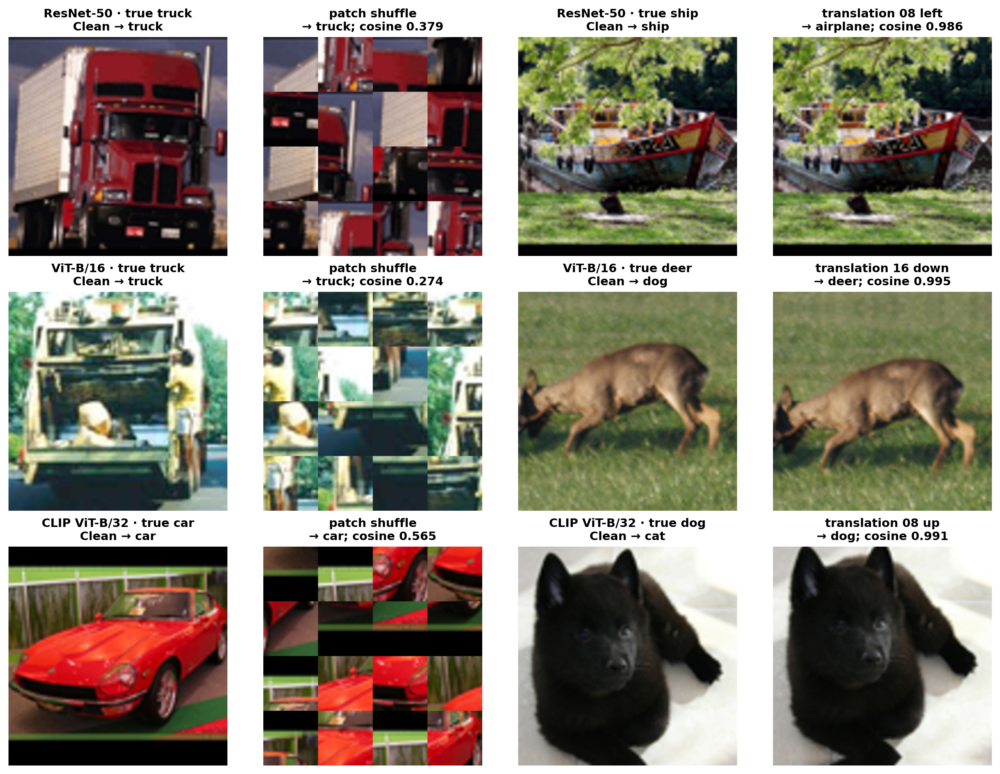

,backbone,condition,pair_index,official_test_index,content_label,cosine_similarity,model,clean_prediction,transformed_prediction,prediction_unchanged
1045,resnet50,patch_shuffle,345,7047,9,0.379,ResNet-50 + linear head,9,9,True
1642,resnet50,translation_08_left,442,4069,8,0.986,ResNet-50 + linear head,8,0,False
8389,vit_b16,patch_shuffle,489,3318,9,0.274,ViT-B/16 + linear head,9,9,True
12232,vit_b16,translation_16_down,332,1960,4,0.995,ViT-B/16 + linear head,5,4,False
16023,clip,patch_shuffle,223,49,2,0.565,CLIP ViT-B/32 + linear head,2,2,True
19211,clip,translation_08_up,411,568,5,0.991,CLIP ViT-B/32 + linear head,3,5,False


In [11]:
selected=[]
for b,m in zip(BACKBONES,MODELS):
    d=pred_pairs[(pred_pairs.backbone==b)&(pred_pairs.model==m)]
    selected.append(d[(d.condition=='patch_shuffle') & d.prediction_unchanged].sort_values('cosine_similarity').iloc[0])
    selected.append(d[d.condition.str.startswith('translation_') & ~d.prediction_unchanged].sort_values('cosine_similarity',ascending=False).iloc[0])
fig,axs=plt.subplots(3,4,figsize=(12,9),layout='constrained')
for k,v in enumerate(selected):
    i=k//2; j=(k%2)*2; x=rgb(v.official_test_index)
    if v.condition=='patch_shuffle':
        idx=int(np.flatnonzero(ids==v.official_test_index)[0]); z=shuffle_patches(x,perms['permutations'][idx])
    else:
        _,amount,direction=v.condition.split('_');dx,dy={'left':(-1,0),'right':(1,0),'up':(0,-1),'down':(0,1)}[direction]
        z=translate_rgb(x,int(amount)*dx,int(amount)*dy)
    show(axs[i,j],x,f'{BNAMES[v.backbone]} · true {classes[int(v.content_label)]}\nClean → {classes[int(v.clean_prediction)]}')
    show(axs[i,j+1],z,f'{v.condition.replace("_"," ")}\n→ {classes[int(v.transformed_prediction)]}; cosine {v.cosine_similarity:.3f}')
figure(fig,'19_mismatch_pairs','Actual paired images showing feature/decision mismatches')
table(pd.DataFrame(selected),'19_selected_mismatches','Exact diagnostic case selection and metrics')


### Saved t-SNE: one fitted coordinate system per backbone

These panels reuse the saved coordinates; there is no new t-SNE fit. Each row is a backbone, each column contrasts one intervention with clean points **from that same joint fit**. Class colors are shared, circles mean clean, and triangles mean transformed. Axis coordinates are not comparable across backbone rows. Local mixing is descriptive; t-SNE distances are not quantitative evidence of feature invariance. Use the cosine table for that claim.

Saved settings: `{"seed": 6304, "perplexity": 30, "max_iter": 1000, "learning_rate": "auto", "metric": "euclidean", "init": "pca", "early_exaggeration": 12, "angle": 0.5, "pca_components": 50, "l2_normalize": true, "conditions": ["grayscale", "cue_conflict", "translation_32_right", "patch_shuffle"]}`

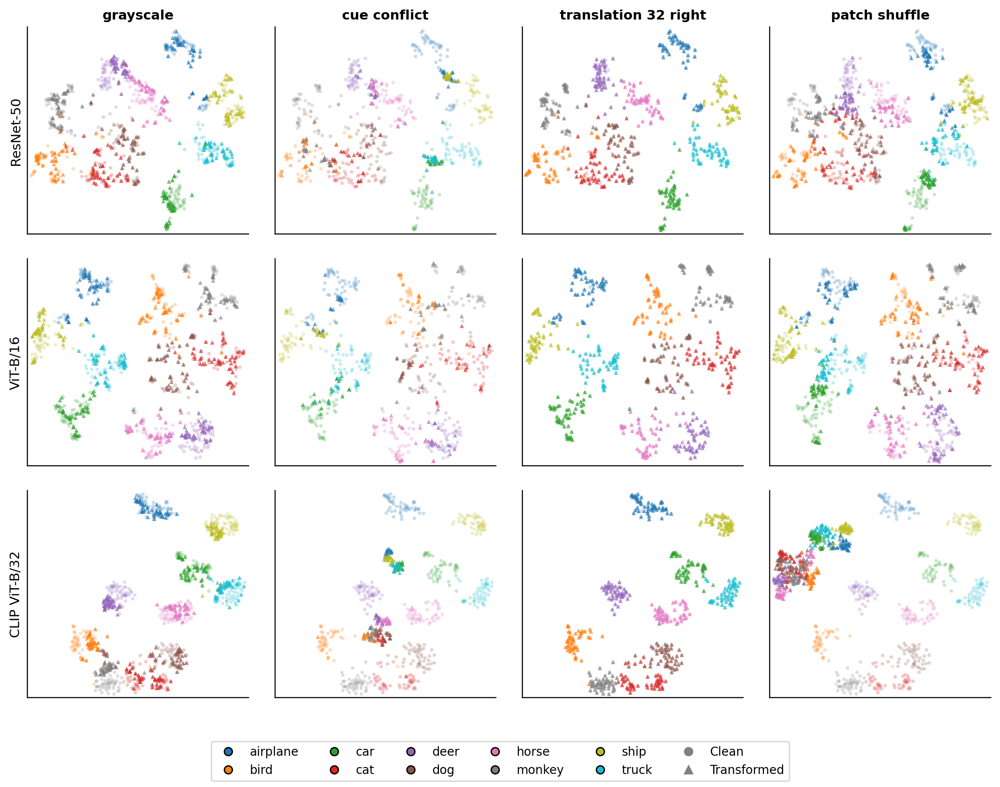

In [12]:
settings_path=RESULTS/'representation_analysis/visualization_settings.json';sources.add(settings_path)
display(Markdown('Saved settings: `'+json.dumps(json.loads(settings_path.read_text()))+'`'))
conditions=['grayscale','cue_conflict','translation_32_right','patch_shuffle']
palette=plt.get_cmap('tab10')
fig,axs=plt.subplots(3,4,figsize=(13,9))
for i,b in enumerate(BACKBONES):
    points=csv(f'representation_analysis/tsne_{b}_points.csv')
    limx=(points.x.min()-2,points.x.max()+2);limy=(points.y.min()-2,points.y.max()+2)
    for j,cond in enumerate(conditions):
        ax=axs[i,j]
        for condition,marker,size,alpha in [('clean','o',7,.25),(cond,'^',10,.65)]:
            d=points[points.condition==condition]
            ax.scatter(d.x,d.y,c=[palette(int(l)) for l in d.label],s=size,marker=marker,alpha=alpha,linewidths=0)
        ax.set(xlim=limx,ylim=limy,xticks=[],yticks=[])
        if i==0:ax.set_title(cond.replace('_',' '),fontsize=10)
        if j==0:ax.set_ylabel(BNAMES[b])
legend=[Line2D([0],[0],marker='o',color='none',markerfacecolor=palette(i),label=c,markersize=6) for i,c in enumerate(classes)]
legend += [Line2D([0],[0],marker='o',color='gray',lw=0,label='Clean'),Line2D([0],[0],marker='^',color='gray',lw=0,label='Transformed')]
fig.legend(handles=legend,loc='lower center',ncol=6,fontsize=9)
fig.subplots_adjust(bottom=.10,wspace=.12,hspace=.12)
figure(fig,'20_joint_tsne','Saved joint embeddings; class colors and clean/transformed markers')


## 9. Each model's evidence, kept separate

Each dossier combines that model's saved performance, shape/texture counts, translation values, and training history where applicable. The prompts underneath distinguish observed measurements from possible mechanisms. They are study aids: verify the mechanism against examples and write your own interpretation.

### ResNet-50

**Possible mechanisms to examine, not established causal conclusions:** ResNet's convolution and pooling provide local aggregation, but do not guarantee invariant final predictions. Check whether its measured translation change is actually large before invoking positional sensitivity. Compare its cue-conflict texture count with its color sensitivity; style transfer can alter color and background as well as texture. A smaller patch penalty can reflect retained local evidence, but does not prove that the model ignores shape. Compare direction-specific cue results and off-pair errors before generalizing.

In [13]:
m=MODELS[0]
table(comparison[comparison.model==SHORT[m]].copy(), '21_model_1_performance', 'Separate performance table for '+SHORT[m])
table(shape[shape.model==m].assign(model=SHORT[m]), '21_model_1_cue', 'Separate cue counts for '+SHORT[m])
table(translation[translation.model==m].assign(model=SHORT[m]), '21_model_1_translation', 'Separate translation results for '+SHORT[m])

h=pd.DataFrame(baseline['training_histories'][BACKBONES[0]]);best=h.loc[h.val_accuracy.idxmax()]
display(Markdown(f"Saved training: **{len(h)} epochs**; selected epoch **{int(best.epoch)}**; best validation accuracy **{100*best.val_accuracy:.2f}%**."))


,model,condition,accuracy_pct,macro_f1_pct,confidence_pct,change_pp,consistency_pct
0,ResNet-50 head,Clean,97.6,97.606,89.784,0.0,100.0
1,ResNet-50 head,Grayscale,95.8,95.783,90.350,-1.8,96.6
2,ResNet-50 head,Hue +0.25,92.8,92.777,88.743,-4.8,94.0
3,ResNet-50 head,Patch shuffle,87.4,87.505,87.109,-10.2,89.8


,model,Nshape,Ntexture,Nother,Ntotal,shape_bias_pct,coverage_pct
0,ResNet-50 head,108,77,15,200,58.378,92.5


,model,displacement,accuracy,prediction_consistency,accuracy_change_pp
8,ResNet-50 head,0,0.976,1.000,0.00
9,ResNet-50 head,8,0.971,0.993,-0.55
10,ResNet-50 head,16,0.968,0.990,-0.80
11,ResNet-50 head,32,0.965,0.987,-1.10


Saved training: **16 epochs**; selected epoch **11**; best validation accuracy **97.20%**.

### ViT-B/16

**Possible mechanisms to examine, not established causal conclusions:** Self-attention permits interactions across the image, while positional embeddings and patch tokenization can introduce sensitivity to layout. Neither feature guarantees a particular shape bias. Compare the measured patch penalty, translation curves and cue coverage rather than assuming a transformer must behave in one way. The 56-pixel intervention patches are not the 16-pixel ViT tokens. ImageNet pretraining and augmentation remain alternative explanations for differences from ResNet.

In [14]:
m=MODELS[1]
table(comparison[comparison.model==SHORT[m]].copy(), '21_model_2_performance', 'Separate performance table for '+SHORT[m])
table(shape[shape.model==m].assign(model=SHORT[m]), '21_model_2_cue', 'Separate cue counts for '+SHORT[m])
table(translation[translation.model==m].assign(model=SHORT[m]), '21_model_2_translation', 'Separate translation results for '+SHORT[m])

h=pd.DataFrame(baseline['training_histories'][BACKBONES[1]]);best=h.loc[h.val_accuracy.idxmax()]
display(Markdown(f"Saved training: **{len(h)} epochs**; selected epoch **{int(best.epoch)}**; best validation accuracy **{100*best.val_accuracy:.2f}%**."))


,model,condition,accuracy_pct,macro_f1_pct,confidence_pct,change_pp,consistency_pct
4,ViT-B/16 head,Clean,97.4,97.389,95.898,0.0,100.0
5,ViT-B/16 head,Grayscale,95.4,95.392,95.316,-2.0,95.0
6,ViT-B/16 head,Hue +0.25,95.0,95.001,92.697,-2.4,94.8
7,ViT-B/16 head,Patch shuffle,90.6,90.640,88.442,-6.8,91.8


,model,Nshape,Ntexture,Nother,Ntotal,shape_bias_pct,coverage_pct
1,ViT-B/16 head,154,37,9,200,80.628,95.5


,model,displacement,accuracy,prediction_consistency,accuracy_change_pp
12,ViT-B/16 head,0,0.974,1.000,0.00
13,ViT-B/16 head,8,0.977,0.981,0.30
14,ViT-B/16 head,16,0.973,0.987,-0.05
15,ViT-B/16 head,32,0.964,0.976,-1.00


Saved training: **24 epochs**; selected epoch **19**; best validation accuracy **98.00%**.

### CLIP with a linear head

**Possible mechanisms to examine, not established causal conclusions:** This head is fitted on unit-normalized image embeddings. A correctly ranked but small true-class margin can produce high accuracy, low maximum softmax confidence, and high cross-entropy simultaneously. Check the saved confidence and early selected epoch before calling the head unsuccessful. Contrast its patch and cue decisions with zero-shot CLIP: the encoder is shared, so disagreements here are about readout rules, not different image features. Image–text pretraining is a possible influence, not an isolated cause established by this experiment.

In [15]:
m=MODELS[2]
table(comparison[comparison.model==SHORT[m]].copy(), '21_model_3_performance', 'Separate performance table for '+SHORT[m])
table(shape[shape.model==m].assign(model=SHORT[m]), '21_model_3_cue', 'Separate cue counts for '+SHORT[m])
table(translation[translation.model==m].assign(model=SHORT[m]), '21_model_3_translation', 'Separate translation results for '+SHORT[m])

h=pd.DataFrame(baseline['training_histories'][BACKBONES[2]]);best=h.loc[h.val_accuracy.idxmax()]
display(Markdown(f"Saved training: **{len(h)} epochs**; selected epoch **{int(best.epoch)}**; best validation accuracy **{100*best.val_accuracy:.2f}%**."))


,model,condition,accuracy_pct,macro_f1_pct,confidence_pct,change_pp,consistency_pct
8,CLIP head,Clean,97.2,97.193,14.197,0.0,100.0
9,CLIP head,Grayscale,95.6,95.564,13.783,-1.6,94.8
10,CLIP head,Hue +0.25,94.6,94.548,13.543,-2.6,94.0
11,CLIP head,Patch shuffle,79.2,79.491,12.337,-18.0,79.0


,model,Nshape,Ntexture,Nother,Ntotal,shape_bias_pct,coverage_pct
2,CLIP head,137,47,16,200,74.457,92.0


,model,displacement,accuracy,prediction_consistency,accuracy_change_pp
0,CLIP head,0,0.972,1.000,0.00
1,CLIP head,8,0.981,0.983,0.90
2,CLIP head,16,0.976,0.978,0.40
3,CLIP head,32,0.970,0.981,-0.25


Saved training: **9 epochs**; selected epoch **4**; best validation accuracy **98.40%**.

### CLIP zero-shot

**Possible mechanisms to examine, not established causal conclusions:** Zero-shot prediction compares the image embedding with fixed class-prompt embeddings; the fitted head learns a boundary from STL-10 labels. Scaled similarities and learned head logits have different confidence scales. Compare paired disagreements, not only aggregate accuracy, to see whether the decision rules differ on the same representation. Zero-shot has no epoch history, and its absence from the training graph is intentional. Fixed prompts are part of the protocol; do not revise them after inspecting test results.

In [16]:
m=MODELS[3]
table(comparison[comparison.model==SHORT[m]].copy(), '21_model_4_performance', 'Separate performance table for '+SHORT[m])
table(shape[shape.model==m].assign(model=SHORT[m]), '21_model_4_cue', 'Separate cue counts for '+SHORT[m])
table(translation[translation.model==m].assign(model=SHORT[m]), '21_model_4_translation', 'Separate translation results for '+SHORT[m])

display(Markdown('**No training epochs:** fixed pretrained image/text encoders and the prescribed class prompts.'))


,model,condition,accuracy_pct,macro_f1_pct,confidence_pct,change_pp,consistency_pct
12,CLIP zero-shot,Clean,96.8,96.752,94.270,0.0,100.0
13,CLIP zero-shot,Grayscale,94.4,94.312,92.694,-2.4,95.4
14,CLIP zero-shot,Hue +0.25,92.6,92.446,91.919,-4.2,93.2
15,CLIP zero-shot,Patch shuffle,77.4,77.773,78.421,-19.4,77.2


,model,Nshape,Ntexture,Nother,Ntotal,shape_bias_pct,coverage_pct
3,CLIP zero-shot,131,48,21,200,73.184,89.5


,model,displacement,accuracy,prediction_consistency,accuracy_change_pp
4,CLIP zero-shot,0,0.968,1.000,0.00
5,CLIP zero-shot,8,0.969,0.981,0.10
6,CLIP zero-shot,16,0.973,0.980,0.45
7,CLIP zero-shot,32,0.956,0.973,-1.20


**No training epochs:** fixed pretrained image/text encoders and the prescribed class prompts.

### Direct CLIP head versus zero-shot agreement

This comparison holds the image encoder fixed. Agreement does not mean correctness; the clean true labels and cue content/style labels answer different questions. The table counts disagreements on identical inputs without fitting or tuning either decision rule.

In [17]:
pair_rows=[]
def agreement(name,a,b):
    a=np.asarray(a);b=np.asarray(b)
    pair_rows.append(dict(condition=name,n=len(a),agreement_pct=100*np.mean(a==b),disagreements=int(np.sum(a!=b))))
agreement('Clean',baseline['clean_logits'][MODELS[2]].argmax(1),baseline['clean_logits'][MODELS[3]].argmax(1))
cp=csv('color_predictions.csv')
for cond in ['grayscale','hue_rotation']:
    a=cp[(cp.model==MODELS[2])&(cp.condition==cond)].set_index('official_test_index').loc[ids]
    b=cp[(cp.model==MODELS[3])&(cp.condition==cond)].set_index('official_test_index').loc[ids]
    agreement(cond,a.predicted_label,b.predicted_label)
agreement('Cue conflict',cue['logits'][MODELS[2]].argmax(1),cue['logits'][MODELS[3]].argmax(1))
pp=csv('patch_shuffle/patch_predictions.csv')
agreement('Patch shuffle',pp[pp.model==MODELS[2]].set_index('official_test_index').loc[ids].predicted_label,
          pp[pp.model==MODELS[3]].set_index('official_test_index').loc[ids].predicted_label)
table(pd.DataFrame(pair_rows),'22_clip_readout_agreement','Paired head-versus-zero-shot decisions on the same image encoder')


,condition,n,agreement_pct,disagreements
0,Clean,500,97.4,13
1,grayscale,500,96.8,16
2,hue_rotation,500,95.4,23
3,Cue conflict,200,81.5,37
4,Patch shuffle,500,86.2,69


## 10. Research-question worksheet (manual p. 5)

These are paraphrased prompts, with the evidence needed to answer them yourself.

| Research question | Evidence in this notebook | Questions to answer in your own words |
|---|---|---|
| RQ1 · What do color and cue conflicts jointly reveal about shape, texture, and color? How does coverage constrain the claim? | Tables 08/10/12, Figures 09/11/13 | Does removing color resemble changing hue? How many cue decisions are excluded from shape bias? Do class-pair directions disagree? Could stylization artifacts explain a case? |
| RQ2 · What happens when spatial structure changes? What does this suggest about locality, global arrangement, and position? | Figures 06/09/14; model dossiers | Contrast translation with patch shuffling. Are the curves monotonic? Which local cues survive shuffling? Which architectural explanations are plausible but unproven? |
| RQ3 · Do prediction and feature changes agree? Include a concrete agreement/mismatch and compare CLIP readouts. | Tables 15/18/19/22; Figures 16–20 | Cite an actual image ID, cosine and prediction pair. Can a changed prediction still be close in feature space? What changes when only the CLIP readout changes? |
| RQ4 · Architecture or pretraining/supervision/augmentation/capacity? | Protocol, all four dossiers, cue and mismatch cases | Which comparison controls the encoder? Which comparisons change several factors? What extra controlled experiment would be needed to identify the cause? |

**Your notes (write here):**

- RQ1: observation → supporting measurement/case → interpretation → limitation.
- RQ2: observation → supporting measurement/case → interpretation → limitation.
- RQ3: observation → supporting measurement/case → interpretation → limitation.
- RQ4: observation → supporting measurement/case → interpretation → limitation.

**Experimental-choice hypotheses:** the manual asks for hypotheses and metrics before interpreting results. Recover your original rationale for STL-10, the five class pairs/style strength, hue +0.25, and t-SNE settings. If it was not recorded prospectively, label any new reasoning as retrospective; do not claim it was a preregistered hypothesis.

## 11. Task 5: how Task 1 will connect to the full report

Task 5 is synthesis, not a fifth training experiment. Its unifying question concerns what representations should preserve, suppress, and reject.

| Task 5 theme | What Task 1 can supply now | Evidence to bring from later tasks before drawing a conclusion |
|---|---|---|
| Visual cues and distribution shift | Color/texture/spatial sensitivities and concrete failures | PACS class-level errors in Tasks 2–3. Compare qualitatively: datasets, models, and training differ, so this is not causal evidence. |
| Invariance versus discriminability | Cases where feature similarity and correct decisions diverge | Domain separability, source/target accuracy and class failures in Tasks 2–3. Feature invariance alone is insufficient evidence. |
| Value of target access | Task 1 provides context, not a test of target access | Shared ERM plus target-aware DAN and target-free DAN-DG. Account for objective/protocol differences and any post-target revisions. |
| Recognition versus rejection | High-confidence transformed mistakes; confidence is not correctness | Vanilla/GCSC/PROSER CSA, near/far rejection and AUROC in Task 4. Task 1's transformed inputs remain known classes; they are not a true OSR test. |
| Overall synthesis | Evidence about preserving class information while tolerating nuisance changes | Combine all tasks to distinguish nuisance variation from genuine out-of-label-space inputs. |

Do not use this notebook to claim that Task 1 directly predicts PACS transfer or OSR performance. Those links require the saved evidence from the other tasks.

## 12. Selecting evidence for the 8-page report

Required main-text Task 1 evidence: compact clean/color/patch comparison; shape/texture/other counts with shape bias and coverage; a translation curve; cosine-stability results and a shared t-SNE/UMAP visualization; informative cue-conflict cases with predictions. All are available here. Learning curves and expanded per-model tables are useful supporting material; select compact panels to fit the full four-task report. An optional appendix cannot replace required main-text evidence.

- Use CSV values rather than copying rounded chart labels when calculating differences.
- Distinguish percentages from percentage points, shape bias from coverage, and cosine from consistency.
- Do not add test-per-epoch curves or uncertainty bands that were never measured. These are single-seed runs; small differences do not establish statistical significance.
- Raw feature stability does not establish semantic or causal invariance; t-SNE does not preserve all distances.
- Document the missing exact stylization settings honestly. The retained review archive is not a substitute for those settings.
- Keep report wording and interpretation your own. Include the GitHub link at the end of the abstract, follow the course NeurIPS template, and keep the main content to 8 pages; references are excluded from that limit.
- Preserve machine-readable results, configurations, split logic/IDs, environment details, and code attribution. Do not commit raw datasets or unnecessary large checkpoints.

**Source guide:** assignment pages 1–5 and 16–17; `configs/protocol.json`; `models/backbones.ipynb`; `data/transforms.ipynb`; the saved result files listed in the provenance manifest below. Study notes explain the actual implementation; they are not a substitute for reading/citing the papers required by the assignment.

In [18]:
def sha256(path):
    h=hashlib.sha256()
    with path.open('rb') as f:
        for chunk in iter(lambda:f.read(8*1024*1024),b''):h.update(chunk)
    return h.hexdigest()
for relative in ['configs/protocol.json','models/backbones.ipynb']:
    sources.add(TASK/relative)
assignment=TASK.parent.parent/'ATML_PA1.pdf'
if assignment.is_file(): sources.add(assignment)
provenance=[]
for path in sorted(sources):
    provenance.append(dict(source=str(path.relative_to(TASK.parent.parent)),bytes=path.stat().st_size,sha256=sha256(path)))
pd.DataFrame(provenance).to_csv(OUT/'source_manifest.csv',index=False)
pd.DataFrame(assets).drop_duplicates('file').to_csv(OUT/'asset_index.csv',index=False)
print(f'Exported {len(set(a["file"] for a in assets))} figures/tables to {OUT}')
print('Source hashes: source_manifest.csv | Output guide: asset_index.csv')
display(pd.DataFrame(assets).drop_duplicates('file'))


Exported 50 figures/tables to D:\LUMS GAMING\6. 2026 Fall\CS 6304\Programming Assignments\PA1\Task 1\task1\report_assets
Source hashes: source_manifest.csv | Output guide: asset_index.csv


,file,purpose
0,01_model_protocol.csv,"Head dimensions, selected epochs, and validati..."
1,02_split_counts.csv,Exact class balance from saved split IDs
2,03_cue_review_counts.csv,Accepted/rejected counts and recorded visual c...
3,04_cue_balance.csv,"Five pairs, both directions, exact retained co..."
4,05_train_test_examples.png,One real training and held-out test example pe...
5,05_train_test_examples.svg,One real training and held-out test example pe...
6,05_example_ids.csv,Official partition IDs for the sample grid
7,06_same_image_interventions.png,Same content image across interventions; style...
8,06_same_image_interventions.svg,Same content image across interventions; style...
9,06_intervention_ids.csv,Image and permutation provenance
